In [79]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [80]:
df = pd.read_csv("weather-check.csv")
df.head()

,RespondentID,Check_Weather_Daily,Check_Weather_Method,Weather_Smartwatch_Likelihood,Age,Gender,Household_Income,US Region
0,3887201482,Yes,The default weather app on your phone,Very likely,30 - 44,Male,"$50,000 to $74,999",South Atlantic
1,3887159451,Yes,The default weather app on your phone,Very likely,18 - 29,Male,Prefer not to answer,South Atlantic
2,3887152228,Yes,The default weather app on your phone,Very likely,30 - 44,Male,"$100,000 to $124,999",Middle Atlantic
3,3887145426,Yes,The default weather app on your phone,Somewhat likely,30 - 44,Male,Prefer not to answer,South Atlantic
4,3887021873,Yes,A specific website or app (please provide the ...,Very likely,30 - 44,Male,"$150,000 to $174,999",Middle Atlantic


In [81]:
df.isnull().sum()

RespondentID                     0
Check_Weather_Daily              0
Check_Weather_Method             0
Weather_Smartwatch_Likelihood    0
Age                              0
Gender                           0
Household_Income                 0
US Region                        0
dtype: int64

In [82]:
df.duplicated().sum()

np.int64(0)

In [83]:
df['Weather_Smartwatch_Likelihood'].value_counts()

Weather_Smartwatch_Likelihood
Very likely          362
Somewhat likely      275
Very unlikely        209
Somewhat unlikely     73
Name: count, dtype: int64

In [84]:
df.columns

Index(['RespondentID', 'Check_Weather_Daily', 'Check_Weather_Method',
       'Weather_Smartwatch_Likelihood', 'Age', 'Gender', 'Household_Income',
       'US Region'],
      dtype='object')

In [85]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   RespondentID                   919 non-null    int64 
 1   Check_Weather_Daily            919 non-null    object
 2   Check_Weather_Method           919 non-null    object
 3   Weather_Smartwatch_Likelihood  919 non-null    object
 4   Age                            919 non-null    object
 5   Gender                         919 non-null    object
 6   Household_Income               919 non-null    object
 7   US Region                      919 non-null    object
dtypes: int64(1), object(7)
memory usage: 57.6+ KB


In [86]:
df.describe()

,RespondentID
count,9.190000e+02
mean,3.879084e+09
std,2.445434e+06
min,3.877567e+09
25%,3.877793e+09
50%,3.878059e+09
75%,3.878700e+09
max,3.887201e+09


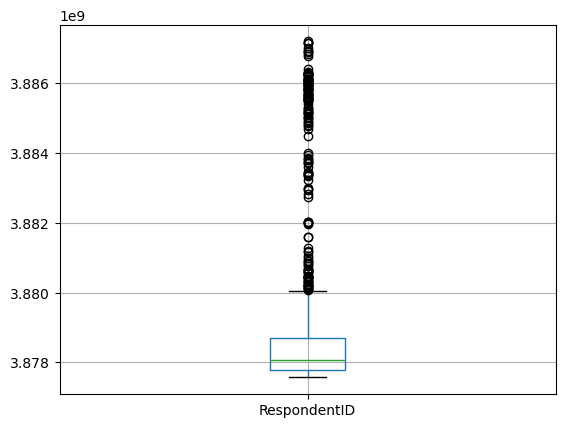

In [87]:
df.select_dtypes(include='number').boxplot()
plt.show()

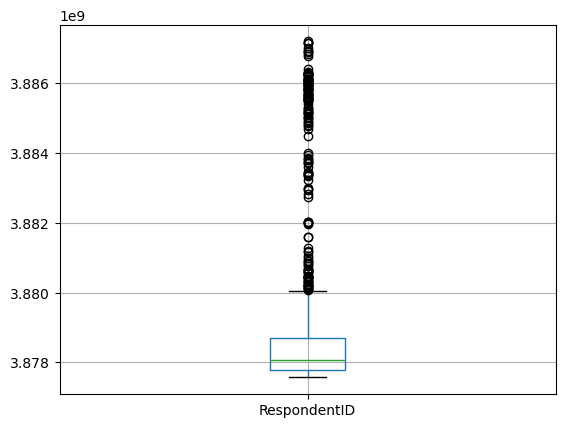

In [88]:
df.boxplot(column='RespondentID')
plt.show()

In [89]:
model = DecisionTreeClassifier()

In [90]:
X = df.drop('Weather_Smartwatch_Likelihood', axis=1)
y = df['Weather_Smartwatch_Likelihood']

In [91]:
X = pd.get_dummies(X, drop_first=True)

In [92]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [93]:
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [94]:
y_pred = model.predict(X_test)

In [95]:
cm = confusion_matrix(y_test, y_pred)

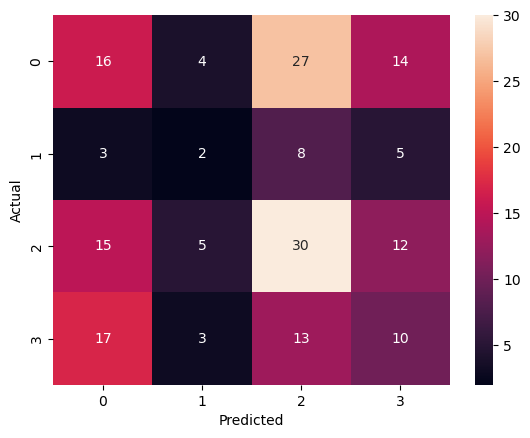

In [96]:
sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [97]:
acc= accuracy_score(y_test,y_pred)
acc

0.31521739130434784

In [98]:
model = RandomForestClassifier(n_estimators=100, random_state=42)

In [99]:
X = df.drop('Weather_Smartwatch_Likelihood', axis=1)
y = df['Weather_Smartwatch_Likelihood']

In [100]:
X = pd.get_dummies(X, drop_first=True)

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [102]:
model.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [103]:
y_pred = model.predict(X_test)

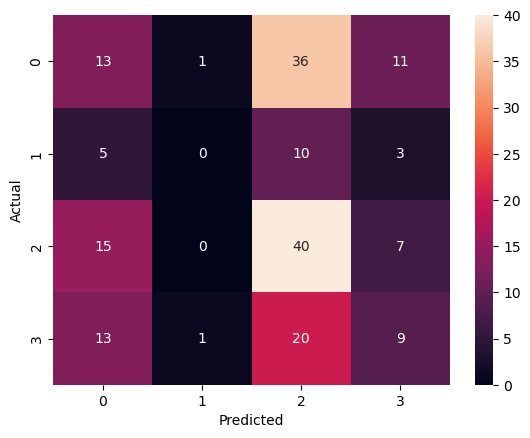

In [104]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [105]:
acc = accuracy_score(y_test, y_pred)
acc

0.33695652173913043

In [106]:
X = df.drop('Weather_Smartwatch_Likelihood', axis=1)
y = df['Weather_Smartwatch_Likelihood']

In [107]:
X = pd.get_dummies(X, drop_first=True)

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [109]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [110]:
model = KNeighborsClassifier(n_neighbors=5)

In [111]:
model.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [112]:
y_pred = model.predict(X_test)

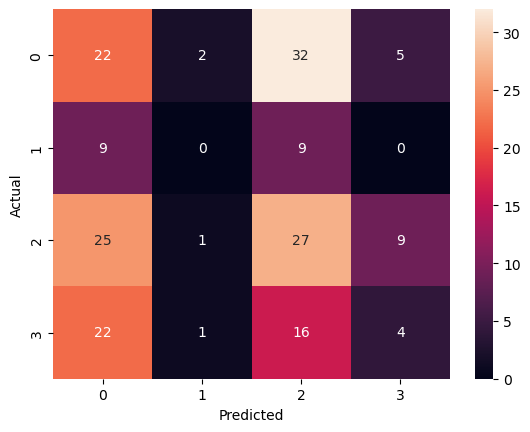

In [113]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)